In [2]:
import numpy as np
from pathlib import Path

data_dir = Path("../data.nosync/60s")

In [3]:
datas = np.concatenate([np.load(f)['values'] for f in data_dir.glob("**/*.npz")], axis=0)
users = np.concatenate([[f'{val}-{str(f).split("/")[-2]}' for val in np.load(f)['groups']] for f in data_dir.glob("**/*.npz")], axis=0)
# datasets = np.concatenate([f.split("/")[-1] for f in data_dir.glob("**/*.npz")], axis=0)

In [4]:
users

array(['U17-SEED-II-Lab', 'U17-SEED-II-Lab', 'U17-SEED-II-Lab', ...,
       'U09-BiHeartS', 'U09-BiHeartS', 'U09-BiHeartS'],
      shape=(477497,), dtype='<U16')

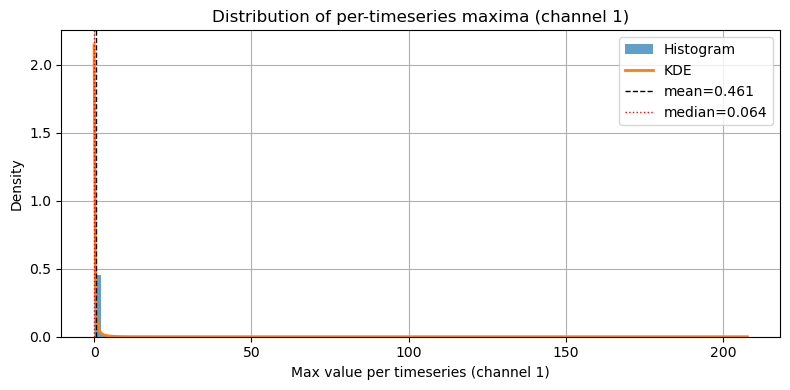

In [5]:
from scipy.stats import gaussian_kde

import matplotlib.pyplot as plt

# compute per-timeseries maximum on channel 1 (index 1)
max_ch1 = datas[:, :, 1].max(axis=1)

plt.figure(figsize=(8, 4))
plt.hist(max_ch1, bins=100, density=True, alpha=0.7, color='C0', label='Histogram')

# overlay KDE if scipy is available
try:
    import numpy as _np  # small local import to build xs
    kde = gaussian_kde(max_ch1)
    xs = _np.linspace(max_ch1.min(), max_ch1.max(), 400)
    plt.plot(xs, kde(xs), color='C1', lw=2, label='KDE')
except Exception:
    pass

mean_val = max_ch1.mean()
median_val = np.median(max_ch1)
plt.axvline(mean_val, color='k', linestyle='--', lw=1, label=f'mean={mean_val:.3f}')
plt.axvline(median_val, color='r', linestyle=':', lw=1, label=f'median={median_val:.3f}')

plt.xlabel('Max value per timeseries (channel 1)')
plt.ylabel('Density')
plt.title('Distribution of per-timeseries maxima (channel 1)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

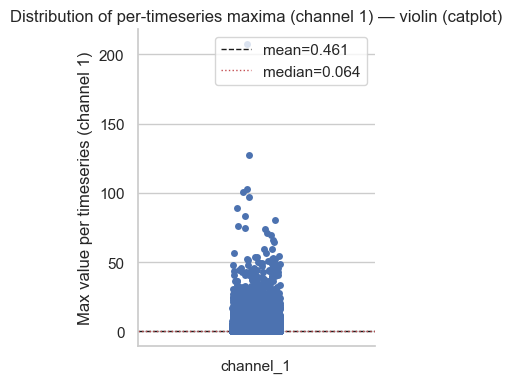

In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# prepare dataframe for seaborn catplot
df = pd.DataFrame({'value': max_ch1, 'category': 'channel_1'})

sns.set(style='whitegrid')
g = sns.catplot(x='category', y='value', data=df,

                height=4, aspect=0.8, color='C0')
ax = g.ax

# add mean and median horizontal lines
ax.axhline(mean_val, color='k', linestyle='--', lw=1, label=f'mean={mean_val:.3f}')
ax.axhline(median_val, color='r', linestyle=':', lw=1, label=f'median={median_val:.3f}')

ax.set_xlabel('')
ax.set_ylabel('Max value per timeseries (channel 1)')
ax.set_title('Distribution of per-timeseries maxima (channel 1) — violin (catplot)')
ax.legend()
plt.tight_layout()
plt.show()


/var/folders/rc/t3h_b88s3vbg5dcd4pnlgskr0000gp/T/ipykernel_58331/592795417.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=counts.index, y=counts.values, palette='viridis')
/var/folders/rc/t3h_b88s3vbg5dcd4pnlgskr0000gp/T/ipykernel_58331/592795417.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(counts.index, rotation=90)


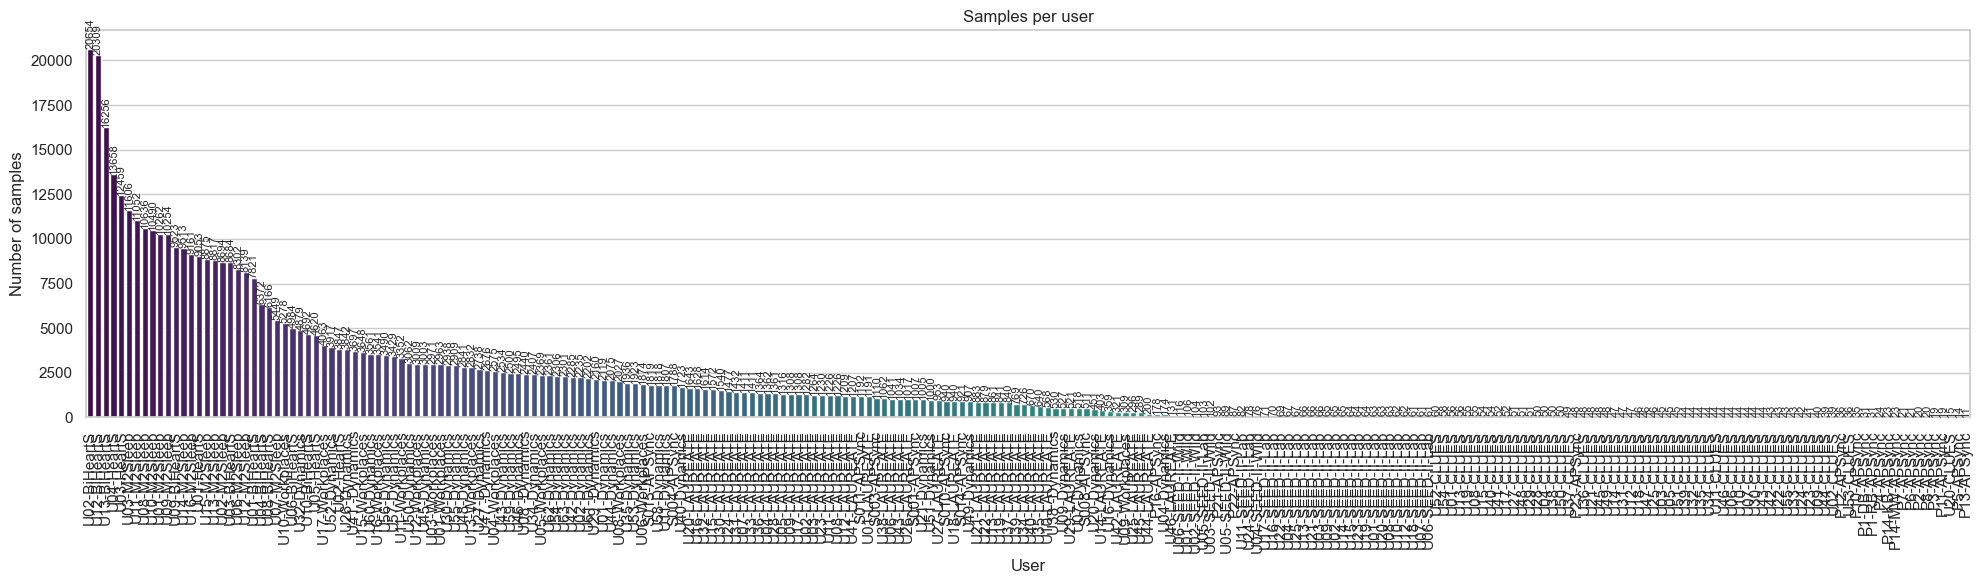

In [7]:
# count samples per user and plot as a barplot
counts = pd.Series(users).value_counts().sort_values(ascending=False)

plt.figure(figsize=(20, 6))
ax = sns.barplot(x=counts.index, y=counts.values, palette='viridis')
ax.set_xticklabels(counts.index, rotation=90)
ax.set_xlabel('User')
ax.set_ylabel('Number of samples')
ax.set_title('Samples per user')

# optional: annotate bars with counts
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=8, rotation=90)

plt.tight_layout()
plt.show()